In [8]:
%load_ext autoreload
%autoreload 2

import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from sklearn.metrics import average_precision_score, precision_recall_curve

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from aml.baseline import evaluate, load_splits, metrics_record, train_search
from aml.config import Config
from aml.io import write_json
from aml.metrics import recall_at_fpr, univariate_screen
from aml.pipeline import compare_with_baseline, run_graph_features
from aml.plotting import LAUNDERING, MUTED, NORMAL, save, set_style

config = Config()
paths = config.paths
FIG = paths.figures_dir
PROC = paths.processed_dir
SEED = config.baseline.seed

set_style()
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [ ]:

graph = run_graph_features(config)
info = json.loads((PROC / "graph_feature_list.json").read_text())
GRAPH_FEATURES, hubs = info["features"], np.array(info["hubs"])

tx = pd.read_parquet(PROC / "transactions.parquet",
                     columns=["tx_id", "from_idx", "to_idx", "payment_format", "is_self_loop"])
assert (tx["tx_id"].to_numpy() == graph["tx_id"].to_numpy()).all()
print(f"{len(GRAPH_FEATURES)} graph features for {len(graph):,} transactions")

13:27:11 | INFO | aml.graph_features | 647,316 distinct edges, 962,284 2-hop and 1,405,067 3-hop paths (11 hubs excluded as intermediaries)
13:29:39 | INFO | aml.graph_features | Built 20 graph features for 5,077,237 transactions
13:29:52 | INFO | aml.pipeline | Wrote 20 graph features to D:\Data Science Projects\IBM Anti-Money Laundering (AML) project\aml-collusion-detection\data\processed\graph_features.parquet
13:29:52 | INFO | aml.pipeline | Top graph features on train by PR-AUC:
                        roc_auc         direction  pr_auc
feature                                                  
cyc4_cnt                 0.5041  higher = riskier  0.0073
cyc3_cnt                 0.5059  higher = riskier  0.0073
cyc4_mins_since_newest   0.5041  higher = riskier  0.0050
cyc3_mins_since_newest   0.5059  higher = riskier  0.0032
rcv_pagerank             0.5478  higher = riskier  0.0019
rcv_in_new_cp_24h        0.5556  higher = riskier  0.0014
fwd2_cnt                 0.5103  higher = riski

20 graph features for 5,077,237 transactions


In [10]:
e = tx[tx["is_self_loop"] == 0]
edges = e[["from_idx", "to_idx"]].drop_duplicates()
print(f"{len(e):,} payments between different accounts -> {len(edges):,} distinct edges "
      f"({len(e) / len(edges):.1f} payments per edge)")

is_hub_sender = tx["from_idx"].isin(hubs)
hub_table = pd.DataFrame({
    "accounts": [len(hubs)],
    "share_of_payments_sent": [is_hub_sender.mean()],
    "laundering_sent": [int(graph.loc[is_hub_sender.to_numpy(), "is_laundering"].sum())],
    "share_of_all_laundering": [graph.loc[is_hub_sender.to_numpy(), "is_laundering"].sum() / graph["is_laundering"].sum()],
}, index=["hubs"])
hub_table

4,486,418 payments between different accounts -> 647,316 distinct edges (6.9 payments per edge)


,accounts,share_of_payments_sent,laundering_sent,share_of_all_laundering
hubs,11,0.0817,584,0.1291


In [11]:
train = graph[graph["split"] == "train"]
y_tr = train["is_laundering"].to_numpy()
base_rate = y_tr.mean()
conditions = {
    "closes a 3-cycle (cyc3 > 0)": train["cyc3_cnt"] > 0,
    "closes a 4-cycle (cyc4 > 0)": train["cyc4_cnt"] > 0,
    "2-hop route S->w->R exists": train["fwd2_cnt"] > 0,
    "3-hop route S->w1->w2->R exists": train["fwd3_cnt"] > 0,
    "sender and receiver already connected": train["same_component"] == 1,
    "sender or receiver is a hub": (train["snd_is_hub"] == 1) | (train["rcv_is_hub"] == 1),
}
paths_table = pd.DataFrame({
    name: {"share_of_payments": m.mean(), "laundering_rate": y_tr[m.to_numpy()].mean(),
           "lift_over_base": y_tr[m.to_numpy()].mean() / base_rate,
           "share_of_laundering_covered": m.to_numpy()[y_tr == 1].mean(),
           "laundering_count": int(y_tr[m.to_numpy()].sum())}
    for name, m in conditions.items()
}).T
print(f"Train base rate: {base_rate:.4%}")
paths_table

Train base rate: 0.0754%


,share_of_payments,laundering_rate,lift_over_base,share_of_laundering_covered,laundering_count
closes a 3-cycle (cyc3 > 0),0.0000,0.2143,284.3006,0.0118,27.0000
closes a 4-cycle (cyc4 > 0),0.0000,0.6333,840.2662,0.0083,19.0000
2-hop route S->w->R exists,0.0082,0.0027,3.5222,0.0287,66.0000
3-hop route S->w1->w2->R exists,0.0089,0.0018,2.3570,0.0209,48.0000
sender and receiver already connected,0.5187,0.0006,0.8372,0.4342,997.0000
sender or receiver is a hub,0.0758,0.0015,1.9477,0.1476,339.0000


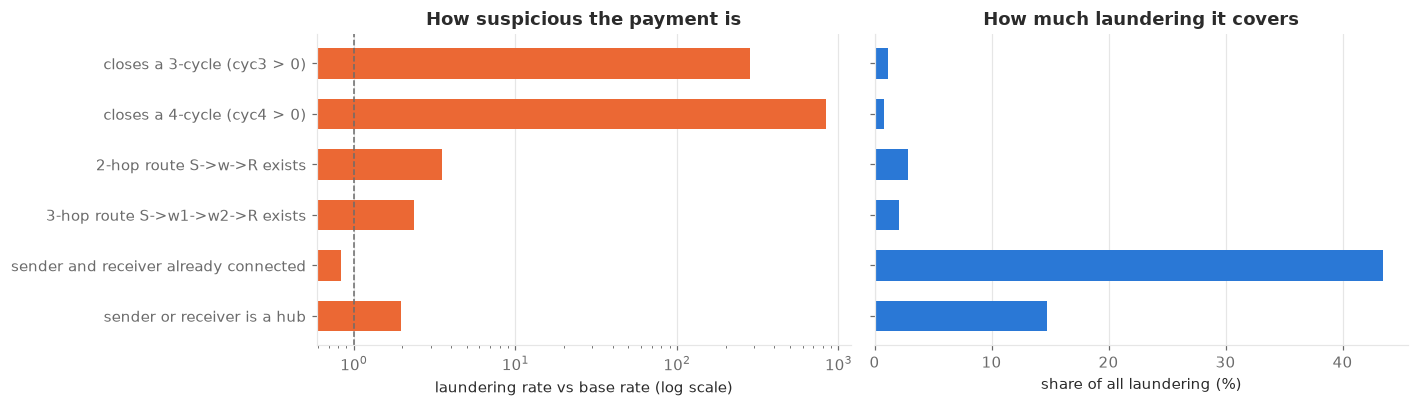

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
order = paths_table.index[::-1]
axes[0].barh(order, paths_table.loc[order, "lift_over_base"], color=LAUNDERING, height=0.6)
axes[0].axvline(1, color=MUTED, linestyle="--", linewidth=1)
axes[0].set_xscale("log")
axes[0].set_xlabel("laundering rate vs base rate (log scale)")
axes[0].set_title("How suspicious the payment is")
axes[1].barh(order, paths_table.loc[order, "share_of_laundering_covered"] * 100, color=NORMAL, height=0.6)
axes[1].set_xlabel("share of all laundering (%)")
axes[1].set_title("How much laundering it covers")
for ax in axes:
    ax.grid(axis="y", visible=False)
plt.tight_layout()
save(fig, FIG, "09_graph_path_signals")
plt.show()

## Graph feature carrying the signal on their own 

Same screening as step 2, on the train split only.

In [13]:
screen = univariate_screen(train, GRAPH_FEATURES)
print(f"Base rate {screen.attrs['base_rate']:.5f}; best step 2 feature had PR-AUC ~0.017")
screen

Base rate 0.00075; best step 2 feature had PR-AUC ~0.017


,roc_auc,direction,pr_auc
feature,,,
cyc4_cnt,0.5041,higher = riskier,0.0073
cyc3_cnt,0.5059,higher = riskier,0.0073
cyc4_mins_since_newest,0.5041,higher = riskier,0.0050
cyc3_mins_since_newest,0.5059,higher = riskier,0.0032
rcv_pagerank,0.5478,higher = riskier,0.0019
rcv_in_new_cp_24h,0.5556,higher = riskier,0.0014
fwd2_cnt,0.5103,higher = riskier,0.0013
snd_pagerank,0.5934,higher = riskier,0.0011
rcv_in_new_cp_1h,0.5160,higher = riskier,0.0010


## XGBoost

In [14]:
FEATURES = json.loads((PROC / "feature_list.json").read_text())["features"]
format_codes = json.loads((PROC / "payment_formats.json").read_text())
ACH = format_codes["ACH"]
patterns = pd.read_parquet(PROC / "pattern_transactions.parquet", columns=["tx_id", "attempt_id", "pattern_type"])

splits = load_splits(PROC / "features.parquet", FEATURES, config.baseline,
                     extra=[(PROC / "graph_features.parquet", GRAPH_FEATURES)])
del graph, train
model, best_params, search_table = train_search(splits, seed=SEED)
search_table

13:30:11 | INFO | aml.baseline | 95 features | train (sampled) (611233, 95) | val (1015300, 95) | test (1015751, 95)
13:35:20 | INFO | aml.baseline | run 0: {'max_depth': 4, 'scale_pos_weight': 1.0} -> val PR-AUC 0.5976 (5.1 min)
13:39:33 | INFO | aml.baseline | run 1: {'max_depth': 6, 'scale_pos_weight': 1.0} -> val PR-AUC 0.5975 (4.2 min)
13:42:33 | INFO | aml.baseline | run 2: {'max_depth': 6, 'scale_pos_weight': 16.285467859863104} -> val PR-AUC 0.5685 (3.0 min)
13:45:31 | INFO | aml.baseline | run 3: {'max_depth': 8, 'scale_pos_weight': 16.285467859863104} -> val PR-AUC 0.5890 (3.0 min)


,max_depth,scale_pos_weight,trees,val_pr_auc,val_roc_auc,val_recall_at_1pct_fpr,minutes
run,,,,,,,
0,4,1.0000,481,0.5976,0.9869,0.8347,5.1392
1,6,1.0000,371,0.5975,0.9874,0.8310,4.2198
3,8,16.2855,214,0.5890,0.9882,0.8412,2.9647
2,6,16.2855,220,0.5685,0.9882,0.8440,2.9958


In [15]:
result = evaluate(model, best_params, search_table, splits, ACH, patterns, config.baseline)
print(f"Selected {best_params}, {model.best_iteration + 1} trees")

Selected {'max_depth': 4, 'scale_pos_weight': 1.0}, 481 trees


## Comparison with the baseline on the test set


In [16]:
base_metrics = json.loads((paths.reports_dir / "metrics_step3_baseline.json").read_text())
base_scores = pd.read_parquet(PROC / "baseline_scores.parquet")
base_test = base_scores[base_scores["split"] == "test"]
test = splits.meta["test"]
assert (base_test["tx_id"].to_numpy() == test["tx_id"].to_numpy()).all()
y_test, score_base, score_graph = splits.y_test, base_test["score"].to_numpy(), result.score_test

g, b = result.test, base_metrics["test"]
gf, bf = result.by_format, base_metrics["test_by_format"]
comparison_table = pd.DataFrame({
    "baseline (step 3)": [b["pr_auc"], b["roc_auc"], b["recall_at_1pct"], b["fpr_at_1pct"],
                          bf["ACH only"]["pr_auc"], bf["all other formats"]["pr_auc"],
                          bf["all other formats"]["recall_at_1pct"]],
    "step 2 + graph": [g["pr_auc"], g["roc_auc"], g["recall_at_1pct"], g["fpr_at_1pct"],
                       gf.loc["ACH only", "pr_auc"], gf.loc["all other formats", "pr_auc"],
                       gf.loc["all other formats", "recall_at_1pct"]],
}, index=["PR-AUC", "ROC-AUC", "recall at 1% budget", "realised FPR at 1% budget",
          "PR-AUC within ACH", "PR-AUC other formats", "recall other formats"])
comparison_table["difference"] = comparison_table["step 2 + graph"] - comparison_table["baseline (step 3)"]
comparison_table

,baseline (step 3),step 2 + graph,difference
PR-AUC,0.5583,0.5669,0.0086
ROC-AUC,0.9868,0.9872,0.0004
recall at 1% budget,0.8478,0.8381,-0.0096
realised FPR at 1% budget,0.0188,0.0128,-0.0060
PR-AUC within ACH,0.6368,0.6466,0.0098
PR-AUC other formats,0.0016,0.0015,-0.0001
recall other formats,0.0139,0.0000,-0.0139


In [17]:
gain = compare_with_baseline(test, y_test, score_graph, result.thresholds[config.baseline.headline_fpr], config)
print(f"{test['timestamp'].dt.floor('h').nunique()} hour blocks, {config.graph.n_bootstrap} bootstrap draws")
gain

56 hour blocks, 200 bootstrap draws


,difference,ci_low,ci_high,share_of_draws_above_0
pr_auc,0.0086,0.0008,0.0159,0.9850
recall_at_equal_fpr,0.0061,-0.0010,0.0140,0.9200
recall_at_threshold,-0.0096,-0.0176,-0.0032,0.0000
alerts_at_threshold,"-6,105.0000","-8,303.8750","-4,282.5750",0.0000


In [18]:
equal_fpr = pd.DataFrame({
    f"{f:.1%} of normal flagged": {"baseline": recall_at_fpr(y_test, score_base, f),
                                   "step 2 + graph": recall_at_fpr(y_test, score_graph, f)}
    for f in config.baseline.fpr_budgets
}).T
equal_fpr["difference"] = equal_fpr["step 2 + graph"] - equal_fpr["baseline"]
equal_fpr

,baseline,step 2 + graph,difference
0.1% of normal flagged,0.5897,0.5871,-0.0026
0.5% of normal flagged,0.7778,0.7874,0.0096
1.0% of normal flagged,0.8259,0.8320,0.0061
2.0% of normal flagged,0.8495,0.8600,0.0105
5.0% of normal flagged,0.8898,0.8906,0.0009


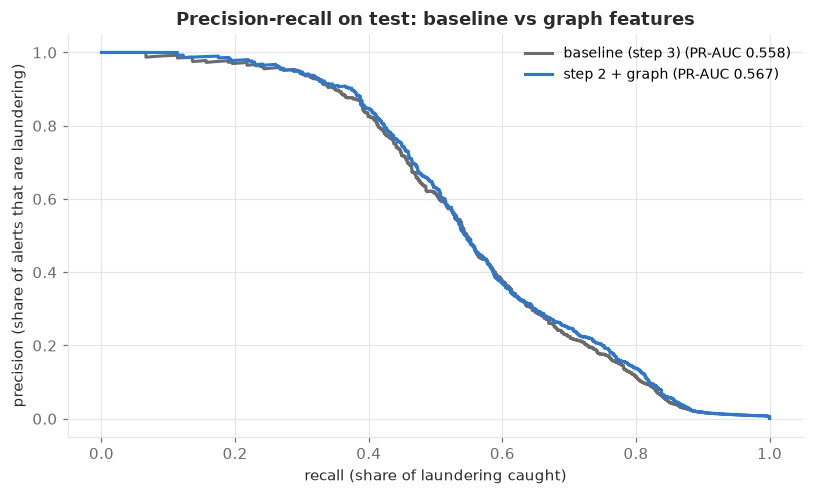

In [19]:
fig, ax = plt.subplots(figsize=(7.5, 4.6))
for name, s, color in [("baseline (step 3)", score_base, MUTED), ("step 2 + graph", score_graph, NORMAL)]:
    p, r, _ = precision_recall_curve(y_test, s)
    ax.plot(r, p, color=color, label=f"{name} (PR-AUC {average_precision_score(y_test, s):.3f})")
ax.set_xlabel("recall (share of laundering caught)")
ax.set_ylabel("precision (share of alerts that are laundering)")
ax.set_title("Precision-recall on test: baseline vs graph features")
ax.legend(loc="upper right", fontsize=9)
plt.tight_layout()
save(fig, FIG, "10_graph_vs_baseline_pr")
plt.show()

In [20]:
gain_share = result.gain_share
graph_gain = gain_share.reindex(GRAPH_FEATURES).fillna(0).sort_values(ascending=False)
print(f"Graph features hold {graph_gain.sum():.1%} of total gain; "
      f"{(graph_gain == 0).sum()} of {len(GRAPH_FEATURES)} are never used.")
print("Top 10 features overall:", ", ".join(gain_share.head(10).index))
graph_gain.to_frame("share_of_gain")

Graph features hold 7.4% of total gain; 7 of 20 are never used.
Top 10 features overall: same_entity, payment_format_code, snd_component_size, pair_prior_cnt, snd_out_cnt_1h, snd_out_distinct_cp_all, is_self_loop, rcv_in_distinct_cp_all, log_amount_usd, pair_reverse_prior_cnt


,share_of_gain
snd_component_size,0.0369
rcv_in_new_cp_1h,0.0057
rcv_pagerank,0.0056
snd_out_new_cp_24h,0.0043
same_component,0.0041
snd_pagerank,0.0032
rcv_component_size,0.0031
rcv_in_new_cp_24h,0.0029
snd_in_new_cp_24h,0.0023
snd_out_new_cp_1h,0.0022


In [21]:
meta = pd.read_parquet(PROC / "features.parquet", columns=["tx_id", "split", "is_laundering", "payment_format_code"])
meta["from_idx"] = tx["from_idx"].to_numpy()
non_ach = meta["payment_format_code"] != ACH
laund_non_ach = meta[non_ach & (meta["is_laundering"] == 1)]
senders = laund_non_ach["from_idx"].value_counts()
top = senders.index[:10]
sender_table = pd.DataFrame({
    "payments_sent": meta[meta["from_idx"].isin(top)].groupby("from_idx").size(),
    "laundering_sent": senders.loc[top],
}).loc[top]
sender_table["laundering_rate"] = sender_table["laundering_sent"] / sender_table["payments_sent"]
print(f"Non-ACH laundering: {len(laund_non_ach):,} payments from {len(senders)} senders; "
      f"the top 10 send {senders.head(10).sum() / len(laund_non_ach):.0%} of it")
sender_table

Non-ACH laundering: 694 payments from 73 senders; the top 10 send 82% of it


,payments_sent,laundering_sent,laundering_rate
from_idx,,,
103,168672,243,0.0014
91402,103018,158,0.0015
213049,20497,29,0.0014
182921,16426,26,0.0016
158259,13756,23,0.0017
165836,17264,21,0.0012
148143,18663,21,0.0011
237784,13073,18,0.0014
175286,14174,16,0.0011


In [ ]:

ids = meta.loc[meta["from_idx"].isin(top) & non_ach & (meta["split"] != "test"), "tx_id"].tolist()

within = pd.read_parquet(PROC / "features.parquet", columns=["tx_id", "is_laundering"] + FEATURES,
                         filters=[("tx_id", "in", ids)])
graph_part = pd.read_parquet(PROC / "graph_features.parquet", columns=["tx_id"] + GRAPH_FEATURES,
                             filters=[("tx_id", "in", ids)])
within = within.merge(graph_part, on="tx_id")
within_screen = univariate_screen(within, FEATURES + GRAPH_FEATURES)
print(f"{len(within):,} payments, laundering rate {within_screen.attrs['base_rate']:.4%}; "
      f"best single-feature ROC-AUC {within_screen['roc_auc'].max():.3f}")
within_screen.sort_values("roc_auc", ascending=False).head(8)

312,673 payments, laundering rate 0.1458%; best single-feature ROC-AUC 0.535


,roc_auc,direction,pr_auc
feature,,,
snd_out_mean_usd_24h,0.5346,higher = riskier,0.0016
snd_in_new_cp_24h,0.5286,higher = riskier,0.0015
snd_in_cnt_24h,0.5286,higher = riskier,0.0015
snd_in_sum_usd_24h,0.5283,higher = riskier,0.0015
snd_in_mean_usd_24h,0.5282,higher = riskier,0.0016
payment_format_code,0.5278,higher = riskier,0.0016
rcv_in_new_cp_24h,0.5271,higher = riskier,0.0016
snd_out_new_cp_24h,0.5259,higher = riskier,0.0015


## Saving the model and metrics

In [23]:
paths.models_dir.mkdir(exist_ok=True)
model.save_model(paths.models_dir / "xgb_graph.json")
record = metrics_record(result, splits, config.baseline, name="XGBoost, step 2 + graph features")
record["n_graph_features"] = len(GRAPH_FEATURES)
record["gain_over_baseline_test"] = gain.to_dict(orient="index")
write_json(record, paths.reports_dir / "metrics_step4_graph.json")
pd.concat([
    splits.meta[name][["tx_id", "is_laundering"]].assign(split=name, score=score)
    for name, score in [("val", result.score_val), ("test", result.score_test)]
]).to_parquet(PROC / "graph_scores.parquet", index=False)
print("Saved models/xgb_graph.json, reports/metrics_step4_graph.json, data/processed/graph_scores.parquet")

Saved models/xgb_graph.json, reports/metrics_step4_graph.json, data/processed/graph_scores.parquet


## Findings

Generated from this run, so the text always matches the numbers above.

In [24]:
d, q, a = gain.loc["pr_auc"], gain.loc["recall_at_equal_fpr"], gain.loc["alerts_at_threshold"]
lines = [
    f"- **Test PR-AUC {g['pr_auc']:.3f}** with graph features vs {b['pr_auc']:.3f} for the baseline "
    f"(difference {d['difference']:+.3f}, 95% interval {d['ci_low']:+.3f} to {d['ci_high']:+.3f}): "
    + ("a real but small gain." if d["ci_low"] > 0 else
       "a worse result than the baseline." if d["ci_high"] < 0 else
       "**not distinguishable from no gain**."),
    f"- **At equal alert volume** (1% of normal test payments flagged) recall changes by {q['difference']:+.1%} "
    f"(interval {q['ci_low']:+.1%} to {q['ci_high']:+.1%}).",
    f"- **In deployment terms** (thresholds fixed on validation): {g['alerts_at_1pct']:,} alerts instead of "
    f"{b['alerts_at_1pct']:,} ({a['difference'] / b['alerts_at_1pct']:+.0%}), precision {g['precision_at_1pct']:.1%} "
    f"vs {b['precision_at_1pct']:.1%}, recall {g['recall_at_1pct']:.1%} vs {b['recall_at_1pct']:.1%}. The graph "
    f"model's threshold drifts less (realised FPR {g['fpr_at_1pct']:.2%} vs {b['fpr_at_1pct']:.2%}).",
    f"- **Cycles are precise but rare**: a payment that closes a 3- or 4-cycle is laundering "
    f"{paths_table.iloc[0]['laundering_rate']:.0%} / {paths_table.iloc[1]['laundering_rate']:.0%} of the time, "
    f"but such payments cover only {paths_table.iloc[0]['share_of_laundering_covered']:.1%} / "
    f"{paths_table.iloc[1]['share_of_laundering_covered']:.1%} of laundering.",
    f"- **Graph features hold {graph_gain.sum():.0%} of the model's gain**; the most used is "
    f"`{graph_gain.index[0]}`.",
    f"- **Other formats stay out of reach**: PR-AUC {gf.loc['all other formats', 'pr_auc']:.4f}. Their laundering "
    f"comes from {len(senders)} senders, mostly a few very large accounts, and no feature separates it "
    f"from their normal payments (best single-feature ROC-AUC {within_screen['roc_auc'].max():.2f}).",
    "- **Implication for step 5**: a GNN sees the same past graph, so its realistic room to improve is "
    "within ACH and in combining signals, not in the non-ACH laundering above.",
]
display(Markdown("\n".join(lines)))

- **Test PR-AUC 0.567** with graph features vs 0.558 for the baseline (difference +0.009, 95% interval +0.001 to +0.016): a real but small gain.
- **At equal alert volume** (1% of normal test payments flagged) recall changes by +0.6% (interval -0.1% to +1.4%).
- **In deployment terms** (thresholds fixed on validation): 13,979 alerts instead of 20,084 (-30%), precision 6.9% vs 4.8%, recall 83.8% vs 84.8%. The graph model's threshold drifts less (realised FPR 1.28% vs 1.88%).
- **Cycles are precise but rare**: a payment that closes a 3- or 4-cycle is laundering 21% / 63% of the time, but such payments cover only 1.2% / 0.8% of laundering.
- **Graph features hold 7% of the model's gain**; the most used is `snd_component_size`.
- **Other formats stay out of reach**: PR-AUC 0.0015. Their laundering comes from 73 senders, mostly a few very large accounts, and no feature separates it from their normal payments (best single-feature ROC-AUC 0.53).
- **Implication for step 5**: a GNN sees the same past graph, so its realistic room to improve is within ACH and in combining signals, not in the non-ACH laundering above.